# IEEE 37-bus standard tap saturation check

## Purpose

Why do both saved DDPG variants choose `(32, 32)` on the validation hours, and what improvement do they miss? This notebook separates achieved performance in saved runs, achievable per-hour voltage performance on the tap grid, and the still-open cause of saturation. It uses the validation split and saved checkpoints. No model is trained here.

In [1]:
from pathlib import Path
import csv
import json
import sys
import time

ROOT = Path.cwd().parents[1]
if not (ROOT / "src/feeder").is_dir():
    raise RuntimeError("Start the kernel in the notebook directory (experiments/<feeder>/).")
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display

from ddpg.checkpoints import load_agent_for_run
from ddpg.ddpg_vvo import raw_to_physical_torch
from common.evaluation import day_row, hour_row, run_day_test
from common.outputs import day_summary
from common.metrics import voltage_metrics
from common.observations import (
    voltage_observation, day_observation, voltage_observation_size, day_observation_size,
)
from feeder.envs import DayEnv, OneShotEnv
from feeder.loads import dataset_feeder, flatten_hours, read_days, scenario_loads
from common.runs import read_run_record
from feeder.simulator import FeederSimulator
from feeder.taps import N_TAPS, PHYSICAL_RANGE, index_of_ratio, ratio_of_index
from common.display import show_table
from common.outputs import daily_summary
from common.plots import plot_static_taps

## Parameters

The sweep writes a new record only when `SWEEP = True`. Set it to `False` to inspect the saved record.

In [2]:
FEEDER = "ieee37std"
DATASET = "ieee37std-random"
SPLIT = "validation"
SEEDS = [0, 1, 2]
SWITCHING_COST_WEIGHT = 1e-5
SWEEP = False
OVERWRITE = False
TIMING_SCENARIOS = 20

## Preflight

Preflight checks paths and records before constructing the simulator or solving a feeder case.

In [3]:
dataset_path = ROOT / "data" / "scenarios" / DATASET / f"{SPLIT}.csv"
sweep_dir = ROOT / "results" / DATASET / "tap_sweep"
sweep_csv = sweep_dir / f"{SPLIT}.csv"
sweep_json = sweep_dir / "sweep.json"
scratch_dir = ROOT / "tmp" / "sweep"
result_base = ROOT / "results" / DATASET
if dataset_feeder(DATASET) != FEEDER:
    raise ValueError("Dataset names a different feeder")
with dataset_path.open(newline="") as handle:
    dataset_rows = list(csv.DictReader(handle))
if len(dataset_rows) != 4800:
    raise ValueError(f"Expected 4800 validation rows, found {len(dataset_rows)}")
expected_ids = [f"{row['day_id']}-h{int(row['hour']):02d}" for row in dataset_rows]
load_columns = [name for name in dataset_rows[0] if name not in ("day_id", "hour")]
dataset_multipliers = [float(row[load_columns[0]]) for row in dataset_rows]
if not all(all(float(row[name]) == multiplier for name in load_columns)
           for row, multiplier in zip(dataset_rows, dataset_multipliers, strict=True)):
    raise ValueError("A dataset row has unequal load factors")
required = []
for seed in SEEDS:
    for algorithm, run in (("ddpg", f"seed{seed}"),
                           ("seq_ddpg", f"b{SWITCHING_COST_WEIGHT}_seed{seed}")):
        path = result_base / algorithm / run
        required += [path / "run.json", path / "train.csv", path / f"{SPLIT}.csv",
                     path / "checkpoints" / "Actor_ddpg",
                     path / "checkpoints" / "Critic_ddpg"]
        if algorithm == "seq_ddpg":
            required.append(path / f"{SPLIT}_hourly.csv")
for controller in ("neutral", "regcontrol"):
    required += [result_base / "reference" / controller / f"{SPLIT}.csv"]
    path = result_base / "seq_reference" / f"{controller}_b{SWITCHING_COST_WEIGHT}"
    required += [path / f"{SPLIT}.csv", path / f"{SPLIT}_hourly.csv"]
missing = [str(path.relative_to(ROOT)) for path in required if not path.is_file()]
if missing:
    raise FileNotFoundError("Missing saved files: " + ", ".join(missing))
if SWEEP:
    if sweep_dir.exists() and not OVERWRITE:
        raise FileExistsError(f"Sweep record already exists: {sweep_dir}")
else:
    if not sweep_csv.is_file() or not sweep_json.is_file():
        raise FileNotFoundError("Sweep record is missing")
    with sweep_json.open() as handle:
        sweep_metadata = json.load(handle)
    for key, value in {"feeder": FEEDER, "dataset": DATASET, "split": SPLIT,
                       "grid": 33, "scenarios": 4800}.items():
        if sweep_metadata.get(key) != value:
            raise ValueError(f"Sweep metadata {key} differs from {value!r}")
    with sweep_csv.open(newline="") as handle:
        recorded_rows = list(csv.DictReader(handle))
    if len(recorded_rows) != 4800:
        raise ValueError("Sweep record does not hold 4800 rows")
    for index, (row, scenario_id, multiplier) in enumerate(
        zip(recorded_rows, expected_ids, dataset_multipliers, strict=True)
    ):
        if row["scenario"] != scenario_id or float(row["multiplier"]) != multiplier:
            raise ValueError(f"Sweep record differs from dataset at row {index}")
print(f"Preflight passed for {len(dataset_rows)} rows and {len(required)} saved files.")
print("No subprocess or feeder solve started before preflight.")

Preflight passed for 4800 rows and 39 saved files.
No subprocess or feeder solve started before preflight.


## Learner checks

These checks verify observation shapes, action projection, tap readback, and numerical solve repeatability.

In [4]:
simulator = FeederSimulator(FEEDER)
days = read_days(DATASET, SPLIT, simulator.load_names, simulator.feeder)
scenarios = flatten_hours(days)
assert [item.id for item in scenarios] == expected_ids
one_env = OneShotEnv(simulator)
day_env = DayEnv(simulator)
assert voltage_observation_size(simulator) == 114
assert day_observation_size(simulator) == 114 + 2 + 2
for seed in SEEDS:
    for algorithm, run, size in (("ddpg", f"seed{seed}", voltage_observation_size(simulator)),
                                 ("seq_ddpg", f"b{SWITCHING_COST_WEIGHT}_seed{seed}", day_observation_size(simulator))):
        path = result_base / algorithm / run
        name = "voltage_observation" if algorithm == "ddpg" else "day_observation"
        read_run_record(path, feeder=FEEDER, dataset=DATASET, algorithm=algorithm,
                        observation_name=name, observation_size=size,
                        action_count=simulator.action_count)
print(f"One-shot observation size: {voltage_observation_size(simulator)}")
print(f"Day observation size: {day_observation_size(simulator)}")
print("First five measurements:", simulator.measurement_names[:5])
print("Last five measurements:", simulator.measurement_names[-5:])

One-shot observation size: 114
Day observation size: 118
First five measurements: ('799.AB', '799.BC', '799.CA', '709.AB', '709.BC')
Last five measurements: ('729.BC', '729.CA', '799r.AB', '799r.BC', '799r.CA')


In [5]:
mapping_rows = []
for raw in (-1.2, -1.0, -0.5, 0.0, 0.5, 0.999, 1.0, 1.2):
    clipped = float(np.clip(raw, -1.0, 1.0))
    proposed = float(raw_to_physical_torch(torch.tensor(raw, dtype=torch.float64), *PHYSICAL_RANGE).item())
    index = int(index_of_ratio(proposed))
    mapping_rows.append({"raw": raw, "clipped": clipped, "physical_ratio": proposed,
                         "tap_index": index, "executed_ratio": float(ratio_of_index(index))})
show_table(mapping_rows, title="Actor output to executed tap index")
raw_max_threshold = (float(ratio_of_index(32)) - 0.5 * 0.00625 - 1.0) / 0.1
assert int(index_of_ratio(raw_to_physical_torch(torch.tensor(raw_max_threshold, dtype=torch.float64), *PHYSICAL_RANGE).item())) == 32
print(f"Smallest raw value mapping to tap 32: {raw_max_threshold:.8f}")

raw,clipped,physical_ratio,tap_index,executed_ratio
-1.2,-1,0.9,0,0.9
-1,-1,0.9,0,0.9
-0.5,-0.5,0.95,8,0.95
0,0,1,16,1
0.5,0.5,1.05,24,1.05
0.999,0.999,1.0999,32,1.1
1,1,1.1,32,1.1
1.2,1,1.1,32,1.1


Smallest raw value mapping to tap 32: 0.96875000


In [6]:
nominal = scenarios[min(range(len(scenarios)), key=lambda i: abs(dataset_multipliers[i] - 1.0))]
kw, kvar = scenario_loads(nominal, simulator)
readback_rows = []
for pair in ((32, 32), (16, 16), (0, 0), (32, 0)):
    result = simulator.solve(kw, kvar, np.asarray(pair, dtype=int))
    assert result.converged
    assert np.array_equal(result.tap_positions, pair)
    assert np.allclose(result.tap_ratios, ratio_of_index(pair), rtol=0.0, atol=1e-9)
    readback_rows.append({"requested": pair, "positions": result.tap_positions,
                          "ratios": result.tap_ratios})
show_table(readback_rows, title=f"Tap readback on {nominal.id}")

requested,positions,ratios
"[32, 32]","[32, 32]","[1.1, 1.1]"
"[16, 16]","[16, 16]","[1, 1]"
"[0, 0]","[0, 0]","[0.9, 0.9]"
"[32, 0]","[32, 0]","[1.1, 0.9]"


The cost tolerance is `1e-12`; the voltage tolerance is `1e-9` p.u. These measure numerical reproducibility. A voltage can lie arbitrarily near a band edge, and a tiny difference can change an exact tie.

In [7]:
ranked = sorted(range(len(scenarios)), key=lambda i: (dataset_multipliers[i], i))
medium = scenarios[ranked[len(ranked) // 2]]
heavy = scenarios[ranked[-1]]
light = scenarios[ranked[0]]
medium_loads = scenario_loads(medium, simulator)
order_results = [simulator.solve(*medium_loads, np.array((20, 12), dtype=int)) for _ in range(3)]
simulator.solve(*scenario_loads(heavy, simulator), np.array((32, 32), dtype=int))
order_results.append(simulator.solve(*medium_loads, np.array((20, 12), dtype=int)))
simulator.solve(*scenario_loads(light, simulator), np.array((0, 0), dtype=int))
order_results.append(simulator.solve(*medium_loads, np.array((20, 12), dtype=int)))
simulator.solve_native_from_case(*scenario_loads(medium, simulator))
order_results.append(simulator.solve(*medium_loads, np.array((20, 12), dtype=int)))
fresh_simulator = FeederSimulator(FEEDER)
order_results.append(fresh_simulator.solve(*scenario_loads(medium, fresh_simulator),
                                          np.array((20, 12), dtype=int)))
cost_difference = max(abs(voltage_metrics(item.voltages, converged=item.converged)["cost"] - voltage_metrics(order_results[0].voltages, converged=order_results[0].converged)["cost"]) for item in order_results)
voltage_difference = max(float(np.max(np.abs(item.voltages - order_results[0].voltages)))
                         for item in order_results)
agreement = {"feasible": len({voltage_metrics(item.voltages, converged=item.converged)["feasible"] for item in order_results}) == 1,
             "violation_count": len({voltage_metrics(item.voltages, converged=item.converged)["violation_count"] for item in order_results}) == 1,
             "positions": all(np.array_equal(item.tap_positions, (20, 12)) for item in order_results)}
print(f"Solve-order check on {medium.id}: {len(order_results)} results across five contexts")
print(f"Maximum absolute cost difference: {cost_difference:.17g}; tolerance 1e-12")
print(f"Maximum absolute voltage difference: {voltage_difference:.17g} p.u.; tolerance 1e-9 p.u.")
print("Agreement:", agreement)
assert cost_difference <= 1e-12 and voltage_difference <= 1e-9
assert all(agreement.values())

Solve-order check on validation-0002-h11: 7 results across five contexts
Maximum absolute cost difference: 0; tolerance 1e-12
Maximum absolute voltage difference: 0 p.u.; tolerance 1e-9 p.u.
Agreement: {'feasible': True, 'violation_count': True, 'positions': True}


## Sweep helper and timing

For each exact factor tuple, the helper visits every tap pair. Failed solves remain counted and cannot win. Equal costs use exact float64 equality. Among ties, choose the smallest distance from `(16, 16)`, then the lexicographically smaller pair.

In [8]:
groups = {}
for scenario in scenarios:
    groups.setdefault(tuple(scenario.factors), []).append(scenario)
distinct_scenarios = [members[0] for members in groups.values()]
print(f"Exact factor groups: {len(groups)}; duplicate rows: {len(scenarios) - len(groups)}")
assert len(groups) == 4793 and len(scenarios) - len(groups) == 7

def sweep_one(scenario, solver):
    kw, kvar = scenario_loads(scenario, solver)
    costs = np.full((N_TAPS, N_TAPS), np.nan, dtype=np.float64)
    feasible = np.zeros((N_TAPS, N_TAPS), dtype=bool)
    converged = np.zeros((N_TAPS, N_TAPS), dtype=bool)
    for k1 in range(N_TAPS):
        for k2 in range(N_TAPS):
            result = solver.solve(kw, kvar, np.array((k1, k2), dtype=int))
            converged[k1, k2] = result.converged
            if result.converged:
                measured = voltage_metrics(result.voltages, converged=result.converged)
                costs[k1, k2] = measured["cost"]
                feasible[k1, k2] = measured["feasible"]
    return costs, feasible, converged

def summarize_grid(costs, feasible, converged):
    count = int(converged.sum())
    row = {"converged_count": count, "failed_count": N_TAPS**2 - count,
           "feasible_count": int(feasible.sum()),
           "cost_at_max": float(costs[32, 32]), "feasible_at_max": bool(feasible[32, 32]),
           "cost_at_neutral": float(costs[16, 16]),
           "feasible_at_neutral": bool(feasible[16, 16])}
    if count:
        minimum = float(np.min(costs[converged]))
        tied = np.argwhere(converged & (costs == minimum))
        best = min(((int(k1), int(k2)) for k1, k2 in tied),
                   key=lambda pair: (abs(pair[0] - 16) + abs(pair[1] - 16), pair))
        row.update(min_cost=minimum, best_k1=best[0], best_k2=best[1],
                   tie_count=len(tied))
    else:
        row.update(min_cost=np.nan, best_k1="", best_k2="", tie_count=0)
    return row

Exact factor groups: 4793; duplicate rows: 7


The timing sample uses evenly spaced ranks of the sorted distinct multipliers, including the lightest and heaviest.

In [9]:
sorted_distinct = sorted(distinct_scenarios, key=lambda item: (item.factors[0], item.id))
timing_indices = np.linspace(0, len(sorted_distinct) - 1, TIMING_SCENARIOS, dtype=int)
timing_sample = [sorted_distinct[int(index)] for index in timing_indices]
assert len({item.id for item in timing_sample}) == TIMING_SCENARIOS
started = time.monotonic()
for item in timing_sample:
    sweep_one(item, simulator)
timing_seconds = time.monotonic() - started
seconds_per_solve = timing_seconds / (TIMING_SCENARIOS * N_TAPS**2)
projected_seconds = seconds_per_solve * len(groups) * N_TAPS**2
scratch_dir.mkdir(parents=True, exist_ok=True)
projection = (f"# Sweep projection\n\nSample size: {TIMING_SCENARIOS} scenarios, "
              f"{TIMING_SCENARIOS * N_TAPS**2} solves.\n\n"
              f"Seconds per solve: {seconds_per_solve:.9f}.\n\n"
              f"Projected wall time for 5,219,577 solves: {projected_seconds:.1f} seconds "
              f"({projected_seconds / 3600:.3f} hours).\n")
(scratch_dir / "projection.md").write_text(projection)
print(projection)

# Sweep projection

Sample size: 20 scenarios, 21780 solves.

Seconds per solve: 0.000359069.

Projected wall time for 5,219,577 solves: 1874.2 seconds (0.521 hours).



In [10]:
SWEEP_COLUMNS = ("scenario", "multiplier", "converged_count", "failed_count", "min_cost",
                 "best_k1", "best_k2", "tie_count", "feasible_count", "cost_at_max",
                 "feasible_at_max", "cost_at_neutral", "feasible_at_neutral")
TIE_RULE = ("Choose the lowest converged cost; exact ties choose the smallest Manhattan "
            "distance from (16, 16), then the lexicographically smaller pair.")
if SWEEP:
    if sweep_dir.exists() and not OVERWRITE:
        raise FileExistsError(f"Sweep record already exists: {sweep_dir}")
    sweep_started = time.monotonic()
    cost_grids, feasible_grids, converged_grids = [], [], []
    summaries = {}
    failed_solves = 0
    for number, scenario in enumerate(distinct_scenarios, start=1):
        costs, feasible, converged = sweep_one(scenario, simulator)
        cost_grids.append(costs)
        feasible_grids.append(feasible)
        converged_grids.append(converged)
        summary = summarize_grid(costs, feasible, converged)
        summaries[tuple(scenario.factors)] = summary
        failed_solves += summary["failed_count"]
        if number % 100 == 0 or number == len(distinct_scenarios):
            elapsed = time.monotonic() - sweep_started
            remaining = elapsed / number * (len(distinct_scenarios) - number)
            progress = (f"Sweep {number}/{len(distinct_scenarios)}: {elapsed:.1f}s elapsed, "
                        f"{remaining:.1f}s remaining")
            print(progress, flush=True)
            with (scratch_dir / "sweep.log").open("a") as progress_log:
                print(progress, file=progress_log, flush=True)
    wall_seconds = time.monotonic() - sweep_started
    np.savez_compressed(scratch_dir / "validation_grid.npz",
                        cost=np.stack(cost_grids), feasible=np.stack(feasible_grids),
                        converged=np.stack(converged_grids),
                        multipliers=np.array([s.factors[0] for s in distinct_scenarios]))
    if sweep_dir.exists() and not OVERWRITE:
        raise FileExistsError(f"Sweep record appeared during execution: {sweep_dir}")
    sweep_dir.mkdir(parents=True, exist_ok=True)
    with sweep_csv.open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=SWEEP_COLUMNS)
        writer.writeheader()
        for scenario in scenarios:
            summary = summaries[tuple(scenario.factors)]
            row = {"scenario": scenario.id, "multiplier": repr(scenario.factors[0]),
                   **summary}
            for name in ("min_cost", "cost_at_max", "cost_at_neutral"):
                row[name] = repr(row[name])
            writer.writerow(row)
    sweep_metadata = {"feeder": FEEDER, "dataset": DATASET, "split": SPLIT,
                      "engine": simulator.engine_version, "grid": N_TAPS,
                      "scenarios": len(scenarios), "distinct_scenarios": len(groups),
                      "solves": len(groups) * N_TAPS**2, "failed_solves": failed_solves,
                      "wall_seconds": wall_seconds, "tie_rule": TIE_RULE}
    sweep_json.write_text(json.dumps(sweep_metadata, indent=2) + "\n")
    print(f"Sweep record written: {sweep_csv} and {sweep_json}")
    print(f"Failed solves: {failed_solves}; all-failed groups: "
          f"{sum(item['converged_count'] == 0 for item in summaries.values())}")
else:
    print(f"Using validated sweep record: {sweep_csv}")

Using validated sweep record: /home/dev/src/ailearn/phd/results/ieee37std-random/tap_sweep/validation.csv


## Achievable voltage performance

The following analysis uses the sweep record and saved validation results.

The join below checks every saved static row against the sweep and the dataset. It counts DDPG actions outside `(32, 32)`.

In [11]:
def read_csv(path):
    with path.open(newline="") as handle:
        return list(csv.DictReader(handle))

sweep_rows = read_csv(sweep_csv)
assert len(sweep_rows) == len(scenarios) == 4800
assert [row["scenario"] for row in sweep_rows] == expected_ids
static_paths = {f"DDPG seed {seed}": result_base / "ddpg" / f"seed{seed}" / f"{SPLIT}.csv"
                for seed in SEEDS}
static_paths.update({name: result_base / "reference" / key / f"{SPLIT}.csv"
                     for name, key in (("RegControl", "regcontrol"), ("Neutral", "neutral"))})
static_rows = {name: read_csv(path) for name, path in static_paths.items()}
for name, rows in {"Sweep": sweep_rows, **static_rows}.items():
    assert len(rows) == 4800
    assert [row["scenario"] for row in rows] == expected_ids
    print(f"Join check {name}: {len(rows)} aligned rows")
static_lookup = {name: {row["scenario"]: row for row in rows}
                 for name, rows in static_rows.items()}
sweep_lookup = {row["scenario"]: row for row in sweep_rows}
not_max_rows = []
for seed in SEEDS:
    for index, row in enumerate(static_rows[f"DDPG seed {seed}"]):
        if (int(row["k1"]), int(row["k2"])) != (32, 32):
            not_max_rows.append({"seed": seed, "scenario": row["scenario"],
                                 "multiplier": dataset_multipliers[index],
                                 "k1": int(row["k1"]), "k2": int(row["k2"])})
print(f"Saved DDPG hours outside (32, 32): {len(not_max_rows)}")
if not_max_rows:
    show_table(not_max_rows, title="Saved DDPG actions outside maximum taps")

Join check Sweep: 4800 aligned rows
Join check DDPG seed 0: 4800 aligned rows
Join check DDPG seed 1: 4800 aligned rows
Join check DDPG seed 2: 4800 aligned rows
Join check RegControl: 4800 aligned rows
Join check Neutral: 4800 aligned rows
Saved DDPG hours outside (32, 32): 0


The table separates the best converged grid cost from the achieved costs. An incomplete grid means the best converged cost is not a certified grid minimum.

In [12]:
multipliers = np.asarray(dataset_multipliers, dtype=float)
bins = [("All hours", np.ones(len(scenarios), dtype=bool))]
for left, right in ((0.5, 0.7), (0.7, 0.9), (0.9, 1.1), (1.1, 1.3), (1.3, 1.5)):
    mask = (multipliers >= left) & (multipliers <= right if right == 1.5 else multipliers < right)
    bins.append((f"[{left}, {right}{']' if right == 1.5 else ')'}", mask))
min_costs = np.asarray([float(row["min_cost"]) for row in sweep_rows])
max_costs = np.asarray([float(row["cost_at_max"]) for row in sweep_rows])
max_feasible = np.asarray([row["feasible_at_max"] in ("True", "1") for row in sweep_rows])
feasible_counts = np.asarray([int(row["feasible_count"]) for row in sweep_rows])
failed_counts = np.asarray([int(row["failed_count"]) for row in sweep_rows])
summary_rows = []
for name, mask in bins:
    indices = np.flatnonzero(mask)
    assert len(indices)
    row = {"loading": name, "hours": len(indices),
           "incomplete-grid hours": int(np.count_nonzero(failed_counts[indices])),
           "mean min cost": float(np.nanmean(min_costs[indices])),
           "maximum min cost": float(np.nanmax(min_costs[indices])),
           "any feasible share (%)": 100 * float(np.mean(feasible_counts[indices] > 0)),
           "(32, 32) mean cost": float(np.nanmean(max_costs[indices])),
           "(32, 32) feasible share (%)": 100 * float(np.mean(max_feasible[indices])),
           "mean max-minus-min": float(np.nanmean(max_costs[indices] - min_costs[indices]))}
    for label, rows in static_rows.items():
        selected = [rows[int(i)] for i in indices]
        row[f"{label} mean cost"] = float(np.mean([float(item["cost"]) for item in selected]))
        row[f"{label} feasible share (%)"] = 100 * float(np.mean([int(item["feasible"]) for item in selected]))
    summary_rows.append(row)
show_table(summary_rows, title="Achievable and achieved hourly voltage performance", max_height=480)
if np.all(feasible_counts > 0):
    feasibility_sentence = "A fully feasible per-hour policy exists on this finite validation set."
elif np.any((feasible_counts == 0) & (failed_counts > 0)):
    feasibility_sentence = ("A fully feasible per-hour policy is unresolved because some hours "
                            "have no found feasible action and incomplete grids.")
else:
    feasibility_sentence = "No fully feasible per-hour policy exists on this finite validation set."
print(feasibility_sentence)
incomplete = int(np.count_nonzero(failed_counts))
if incomplete:
    print(f"Hours with incomplete grids: {incomplete}. Their min cost is best converged, "
          "and zero feasible count cannot prove infeasibility. A found feasible action "
          "still proves feasibility. Minimum and infeasibility claims apply only to complete grids.")
else:
    print("Hours with incomplete grids: 0. All per-hour minima and infeasibility claims "
          "are certified on the complete finite grid.")

loading,hours,incomplete-grid hours,mean min cost,maximum min cost,any feasible share (%),"(32, 32) mean cost","(32, 32) feasible share (%)",mean max-minus-min,DDPG seed 0 mean cost,DDPG seed 0 feasible share (%),DDPG seed 1 mean cost,DDPG seed 1 feasible share (%),DDPG seed 2 mean cost,DDPG seed 2 feasible share (%),RegControl mean cost,RegControl feasible share (%),Neutral mean cost,Neutral feasible share (%)
All hours,4800,0,0.000217501976448,0.00143701208091,19.25,0.000219653640853,0,2.15166440524e-06,0.000219653640853,0,0.000219653640853,0,0.000219653640853,0,0.0002177435628,17.1041666667,0.00299035134959,0
"[0.5, 0.7)",957,0,1.04839264074e-10,6.81245109142e-09,96.5517241379,1.01912743239e-05,0,1.01911694846e-05,1.01912743239e-05,0,1.01912743239e-05,0,1.01912743239e-05,0,2.59324521783e-09,85.78892372,0.000232206043455,0
"[0.7, 0.9)",974,0,1.77294928181e-06,5.45582319468e-06,0,2.26806995242e-06,0,4.95120670615e-07,2.26806995242e-06,0,2.26806995242e-06,0,2.26806995242e-06,0,2.00952234433e-06,0,0.00102942051207,0
"[0.9, 1.1)",956,0,1.62323427324e-05,4.32291194463e-05,0,1.63294059282e-05,0,9.70631957962e-08,1.63294059282e-05,0,1.63294059282e-05,0,1.63294059282e-05,0,1.72018102261e-05,0,0.00246073562694,0
"[1.1, 1.3)",968,0,0.000193286182845,0.00044199436681,0,0.000193286182845,0,0,0.000193286182845,0,0.000193286182845,0,0.000193286182845,0,0.000193286182845,0,0.00440148290513,0
"[1.3, 1.5]",945,0,0.000888532687166,0.00143701208091,0,0.000888532687166,0,0,0.000888532687166,0,0.000888532687166,0,0.000888532687166,0,0.000888532687166,0,0.00689493227956,0


No fully feasible per-hour policy exists on this finite validation set.
Hours with incomplete grids: 0. All per-hour minima and infeasibility claims are certified on the complete finite grid.


The tap plot orders independent hours by loading multiplier. The cost plot compares the best grid action with maximum taps on the same hours.

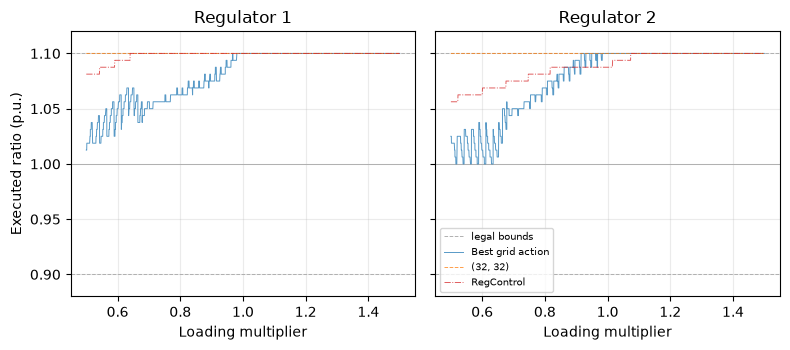

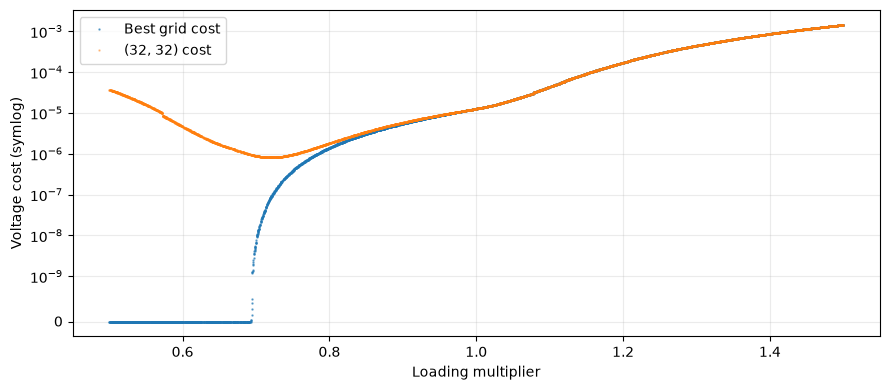

In [13]:
best_plot_rows = [{"k1": row["best_k1"], "k2": row["best_k2"]} for row in sweep_rows]
max_plot_rows = [{"k1": 32, "k2": 32} for _ in sweep_rows]
fig, axes = plot_static_taps(
    scenarios, {"Best grid action": best_plot_rows, "(32, 32)": max_plot_rows,
                "RegControl": static_rows["RegControl"]},
    ["Best grid action", "(32, 32)", "RegControl"],
    {"Best grid action": "#1f77b4", "(32, 32)": "#ff7f0e", "RegControl": "#d62728"}, 2)
plt.show()
fig, ax = plt.subplots(figsize=(9, 4), dpi=100)
order = np.argsort(multipliers, kind="stable")
ax.plot(multipliers[order], min_costs[order], ".", ms=1.5, alpha=0.6, label="Best grid cost")
ax.plot(multipliers[order], max_costs[order], ".", ms=1.5, alpha=0.4, label="(32, 32) cost")
ax.set_yscale("symlog", linthresh=1e-9)
ax.set(xlabel="Loading multiplier", ylabel="Voltage cost (symlog)")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## Learner inspection

The following analysis inspects saved actor and critic checkpoints.

Five validation hours span the sorted loading range. The selected hours anchor both actor and critic checks.

In [14]:
rank_fractions = (("light", 0.0), ("10%", 0.1), ("median", 0.5),
                  ("90%", 0.9), ("heavy", 1.0))
representatives = [(label, scenarios[ranked[int(fraction * (len(ranked) - 1))]])
                   for label, fraction in rank_fractions]
show_table([{"rank": label, "scenario": scenario.id,
             "multiplier": scenario.factors[0]} for label, scenario in representatives],
           title="Representative validation hours")

rank,scenario,multiplier
light,validation-0128-h15,0.500193
10%,validation-0100-h13,0.593315
median,validation-0134-h14,0.998294
90%,validation-0007-h19,1.397915
heavy,validation-0084-h13,1.499951


The one-shot critic trains on executed physical ratios, not raw actor values or indices. With gamma zero, its target is the immediate reward, `-1000 × voltage cost`. Higher critic values indicate better predicted reward.

In [15]:
import gc

def make_agent(kind, seed):
    env_size = voltage_observation_size(simulator) if kind == "ddpg" else day_observation_size(simulator)
    name = "voltage_observation" if kind == "ddpg" else "day_observation"
    run = f"seed{seed}" if kind == "ddpg" else f"b{SWITCHING_COST_WEIGHT}_seed{seed}"
    agent, _task = load_agent_for_run(
        result_base / kind / run, feeder=FEEDER, dataset=DATASET, algorithm=kind,
        observation_name=name, observation_size=env_size,
        action_count=simulator.action_count, action_bounds=PHYSICAL_RANGE,
    )
    return agent

def raw_actor(agent, observation):
    with torch.no_grad():
        tensor = torch.as_tensor(observation, dtype=torch.float32, device=agent.device)
        return agent.actor(tensor).cpu().numpy().astype(float)

def critic_value(agent, observation, positions):
    with torch.no_grad():
        state = torch.as_tensor(observation, dtype=torch.float32, device=agent.device)
        action = torch.as_tensor(ratio_of_index(positions), dtype=torch.float32,
                                 device=agent.device)
        return float(agent.critic(state, action).item())

def action_chain(raw):
    clipped = np.clip(raw, -1.0, 1.0)
    physical = raw_to_physical_torch(torch.as_tensor(raw, dtype=torch.float64), *PHYSICAL_RANGE).numpy()
    indices = index_of_ratio(physical)
    return clipped, physical, indices

Raw one-shot outputs and critic predictions use the saved checkpoints. Each measured reward comes from a fresh fixed-tap solve at the neutral-reset scenario.

seed,rank,scenario,raw,clipped,physical ratios,executed indices
0,light,validation-0128-h15,"[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
0,10%,validation-0100-h13,"[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
0,median,validation-0134-h14,"[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
0,90%,validation-0007-h19,"[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
0,heavy,validation-0084-h13,"[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
1,light,validation-0128-h15,"[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
1,10%,validation-0100-h13,"[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
1,median,validation-0134-h14,"[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
1,90%,validation-0007-h19,"[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
1,heavy,validation-0084-h13,"[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"


seed,rank,scenario,action,indices,predicted reward,measured reward,measured cost
0,light,validation-0128-h15,"(32, 32)","[32, 32]",-0.00826440006495,-0.0372009870557,3.72009870557e-05
0,light,validation-0128-h15,RegControl,"[29, 25]",-0.00345808267593,-0,0
0,light,validation-0128-h15,best grid,"[18, 20]",-0.00718746334314,-0,0
0,10%,validation-0100-h13,"(32, 32)","[32, 32]",-0.00364556908607,-0.00540342813777,5.40342813777e-06
0,10%,validation-0100-h13,RegControl,"[31, 26]",0.000639386475086,-0,0
0,10%,validation-0100-h13,best grid,"[21, 21]",-0.00497610867023,-0,0
0,median,validation-0134-h14,"(32, 32)","[32, 32]",-0.00662712007761,-0.012581799589,1.2581799589e-05
0,median,validation-0134-h14,RegControl,"[32, 30]",-0.00703446567059,-0.0134693825641,1.34693825641e-05
0,median,validation-0134-h14,best grid,"[32, 32]",-0.00662712007761,-0.012581799589,1.2581799589e-05
0,90%,validation-0007-h19,"(32, 32)","[32, 32]",-0.789759278297,-0.855542345308,0.000855542345308


seed,critic prefers max where alternative measures better
0,1
1,4
2,4


One-shot critic-prefers-maximum-where-worse cases: 9
One-shot raw actor ranges by seed and regulator:
seed 0, regulator 1: min 1, max 1
seed 0, regulator 2: min 1, max 1
seed 1, regulator 1: min 1, max 1
seed 1, regulator 2: min 1, max 1
seed 2, regulator 1: min 1, max 1
seed 2, regulator 2: min 1, max 1


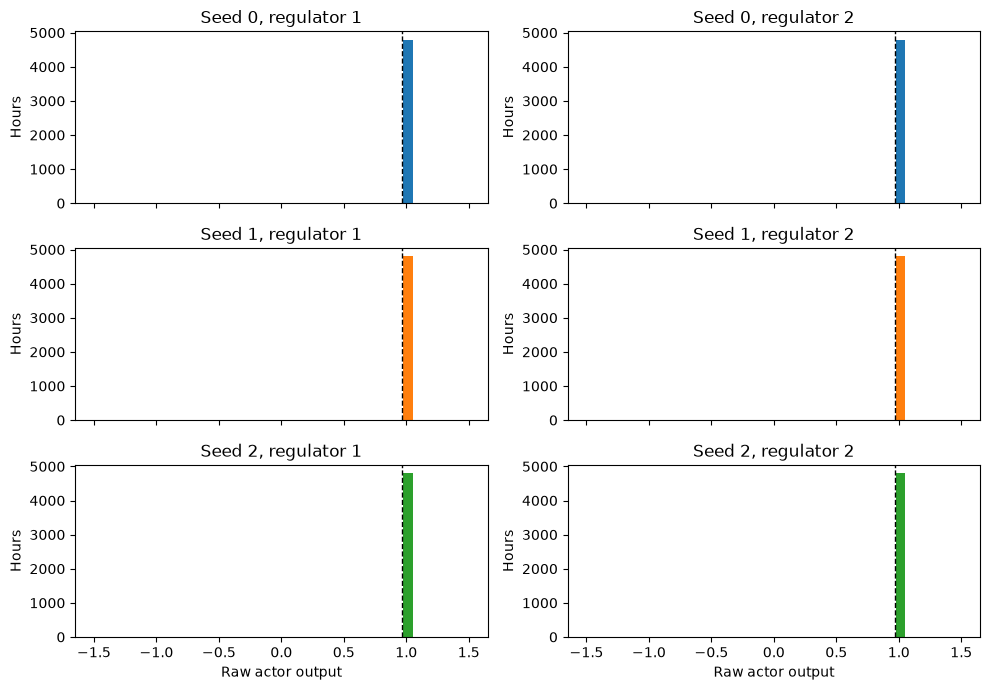

variant,seed,regulator,share at or above tap-32 threshold (%)
one-shot,0,1,100
one-shot,0,2,100
one-shot,1,1,100
one-shot,1,2,100
one-shot,2,1,100
one-shot,2,2,100


In [16]:
one_actor_rows = []
one_raw = {}
one_critic_rows = []
critic_bad = []
measured_cache = {}
for seed in SEEDS:
    agent = make_agent("ddpg", seed)
    for rank_label, scenario in representatives:
        observation = voltage_observation(one_env.reset(scenario))
        raw = raw_actor(agent, observation)
        clipped, physical, indices = action_chain(raw)
        one_actor_rows.append({"seed": seed, "rank": rank_label, "scenario": scenario.id,
                               "raw": raw, "clipped": clipped, "physical ratios": physical,
                               "executed indices": indices})
        saved_reg = static_lookup["RegControl"][scenario.id]
        sweep = sweep_lookup[scenario.id]
        actions = {"(32, 32)": (32, 32),
                   "RegControl": (int(saved_reg["k1"]), int(saved_reg["k2"])),
                   "best grid": (int(sweep["best_k1"]), int(sweep["best_k2"]))}
        predictions = {}
        costs = {}
        for label, pair in actions.items():
            key = (scenario.id, pair)
            if key not in measured_cache:
                measured = simulator.solve(*scenario_loads(scenario, simulator),
                                           np.asarray(pair, dtype=int))
                assert measured.converged
                measured_cache[key] = voltage_metrics(measured.voltages, converged=measured.converged)["cost"]
            cost = measured_cache[key]
            q = critic_value(agent, observation, pair)
            predictions[label], costs[label] = q, cost
            one_critic_rows.append({"seed": seed, "rank": rank_label,
                                    "scenario": scenario.id, "action": label,
                                    "indices": pair, "predicted reward": q,
                                    "measured reward": -1000.0 * cost,
                                    "measured cost": cost})
        for alternative in ("RegControl", "best grid"):
            if costs[alternative] < costs["(32, 32)"] and predictions["(32, 32)"] > predictions[alternative]:
                critic_bad.append({"seed": seed, "rank": rank_label,
                                   "scenario": scenario.id, "better action": alternative})
    raw_values = []
    for scenario in scenarios:
        observation = voltage_observation(one_env.reset(scenario))
        raw_values.append(raw_actor(agent, observation))
    one_raw[seed] = np.asarray(raw_values)
    del agent
    gc.collect()
show_table(one_actor_rows, title="One-shot raw outputs and executed actions", max_height=430)
show_table(one_critic_rows, title="One-shot critic versus fresh measured reward", max_height=480)
show_table([{"seed": seed, "critic prefers max where alternative measures better":
             sum(row["seed"] == seed for row in critic_bad)} for seed in SEEDS],
           title="One-shot critic ranking conflicts")
print(f"One-shot critic-prefers-maximum-where-worse cases: {len(critic_bad)}")
raw_bin_edges = np.linspace(-1.5, 1.5, 41)
print("One-shot raw actor ranges by seed and regulator:")
for seed in SEEDS:
    for regulator in range(2):
        values = one_raw[seed][:, regulator]
        print(f"seed {seed}, regulator {regulator + 1}: "
              f"min {np.min(values):.17g}, max {np.max(values):.17g}")
fig, axes = plt.subplots(len(SEEDS), 2, figsize=(10, 7), dpi=100, sharex=True)
one_shares = {}
for row_index, seed in enumerate(SEEDS):
    for regulator in range(2):
        axis = axes[row_index, regulator]
        axis.hist(one_raw[seed][:, regulator], bins=raw_bin_edges, color=f"C{seed}")
        one_shares[(seed, regulator)] = float(np.mean(one_raw[seed][:, regulator] >= raw_max_threshold))
        axis.axvline(raw_max_threshold, color="black", linestyle="--", linewidth=1)
        axis.set(title=f"Seed {seed}, regulator {regulator + 1}", ylabel="Hours")
        if row_index == len(SEEDS) - 1:
            axis.set_xlabel("Raw actor output")
fig.tight_layout()
plt.show()
show_table([{"variant": "one-shot", "seed": seed, "regulator": regulator + 1,
             "share at or above tap-32 threshold (%)": 100 * one_shares[(seed, regulator)]}
            for seed in SEEDS for regulator in range(2)],
           title="One-shot raw saturation shares")

The sequential critic estimates remaining-day return at the policy's actual hour and tap state. Its values are not immediate voltage costs.

seed,rank,scenario,hour,observation tap state,raw,clipped,physical ratios,executed indices
0,light,validation-0128-h15,15,"[32, 32]","[0.999999940395, 1]","[0.999999940395, 1]","[1.09999999404, 1.1]","[32, 32]"
0,10%,validation-0100-h13,13,"[32, 32]","[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
0,median,validation-0134-h14,14,"[32, 32]","[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
0,90%,validation-0007-h19,19,"[32, 32]","[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
0,heavy,validation-0084-h13,13,"[32, 32]","[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
1,light,validation-0128-h15,15,"[32, 32]","[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
1,10%,validation-0100-h13,13,"[32, 32]","[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
1,median,validation-0134-h14,14,"[32, 32]","[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
1,90%,validation-0007-h19,19,"[32, 32]","[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"
1,heavy,validation-0084-h13,13,"[32, 32]","[1, 1]","[1, 1]","[1.1, 1.1]","[32, 32]"


seed,rank,scenario,observation tap state,action,indices,estimated remaining-day return,ranking
0,light,validation-0128-h15,"[32, 32]","(32, 32)","[32, 32]",-1.84590816498,"(32, 32) > RegControl > best grid"
0,light,validation-0128-h15,"[32, 32]",RegControl,"[29, 25]",-1.88526797295,"(32, 32) > RegControl > best grid"
0,light,validation-0128-h15,"[32, 32]",best grid,"[18, 20]",-2.27892684937,"(32, 32) > RegControl > best grid"
0,10%,validation-0100-h13,"[32, 32]","(32, 32)","[32, 32]",-2.23564577103,"(32, 32) > RegControl > best grid"
0,10%,validation-0100-h13,"[32, 32]",RegControl,"[31, 26]",-2.26143717766,"(32, 32) > RegControl > best grid"
0,10%,validation-0100-h13,"[32, 32]",best grid,"[21, 21]",-2.55715370178,"(32, 32) > RegControl > best grid"
0,median,validation-0134-h14,"[32, 32]","(32, 32)","[32, 32]",-1.98450469971,"(32, 32) = best grid > RegControl"
0,median,validation-0134-h14,"[32, 32]",RegControl,"[32, 30]",-1.99395036697,"(32, 32) = best grid > RegControl"
0,median,validation-0134-h14,"[32, 32]",best grid,"[32, 32]",-1.98450469971,"(32, 32) = best grid > RegControl"
0,90%,validation-0007-h19,"[32, 32]","(32, 32)","[32, 32]",-1.66263628006,"(32, 32) = RegControl = best grid"


Sequential saved-hourly mismatch counts: {0: 0, 1: 0, 2: 0} ; total: 0
Sequential raw actor ranges by seed and regulator:
seed 0, regulator 1: min 0.99999994039535522, max 1
seed 0, regulator 2: min 1, max 1
seed 1, regulator 1: min 1, max 1
seed 1, regulator 2: min 1, max 1
seed 2, regulator 1: min 1, max 1
seed 2, regulator 2: min 0.99999994039535522, max 1


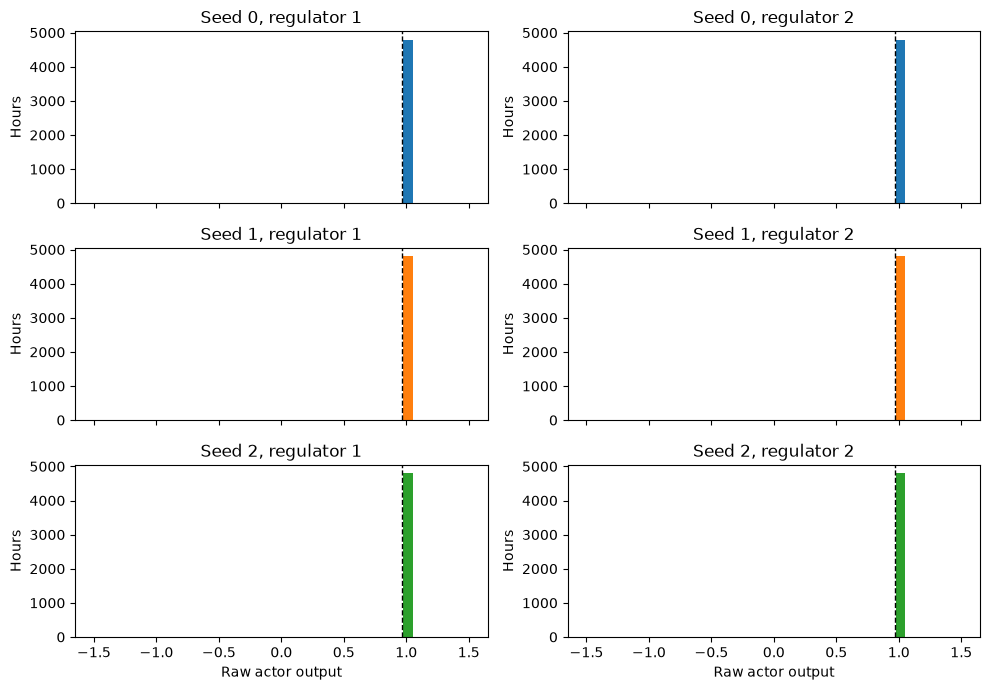

variant,seed,regulator,share at or above tap-32 threshold (%)
one-shot,0,1,100
one-shot,0,2,100
one-shot,1,1,100
one-shot,1,2,100
one-shot,2,1,100
one-shot,2,2,100
sequential,0,1,100
sequential,0,2,100
sequential,1,1,100
sequential,1,2,100


In [17]:
day_lookup = {day.id: day for day in days}
seq_actor_rows = []
seq_critic_rows = []
seq_raw = {}
seq_shares = {}
seq_mismatches = {}
for seed in SEEDS:
    agent = make_agent("seq_ddpg", seed)
    env = DayEnv(simulator)
    for rank_label, scenario in representatives:
        observation = day_observation(env.reset(day_lookup[scenario.day_id]))
        while env.hour < scenario.hour:
            positions = index_of_ratio(agent.choose_action_deterministic(observation))
            next_state, _, _ = env.step(positions)
            observation = day_observation(next_state)
        assert env.hour == scenario.hour
        prior = env.tap_positions
        raw = raw_actor(agent, observation)
        clipped, physical, indices = action_chain(raw)
        seq_actor_rows.append({"seed": seed, "rank": rank_label, "scenario": scenario.id,
                               "hour": env.hour, "observation tap state": prior,
                               "raw": raw, "clipped": clipped,
                               "physical ratios": physical, "executed indices": indices})
        saved_reg = static_lookup["RegControl"][scenario.id]
        sweep = sweep_lookup[scenario.id]
        actions = {"(32, 32)": (32, 32),
                   "RegControl": (int(saved_reg["k1"]), int(saved_reg["k2"])),
                   "best grid": (int(sweep["best_k1"]), int(sweep["best_k2"]))}
        predictions = {label: critic_value(agent, observation, pair)
                       for label, pair in actions.items()}
        ordered_actions = sorted(predictions, key=predictions.get, reverse=True)
        rank_groups = []
        for label in ordered_actions:
            if rank_groups and predictions[label] == predictions[rank_groups[-1][0]]:
                rank_groups[-1].append(label)
            else:
                rank_groups.append([label])
        ranking = " > ".join(" = ".join(group) for group in rank_groups)
        for label, pair in actions.items():
            seq_critic_rows.append({"seed": seed, "rank": rank_label,
                                    "scenario": scenario.id, "observation tap state": prior,
                                    "action": label, "indices": pair,
                                    "estimated remaining-day return": predictions[label],
                                    "ranking": ranking})
    saved_hourly = read_csv(result_base / "seq_ddpg" /
                            f"b{SWITCHING_COST_WEIGHT}_seed{seed}" / f"{SPLIT}_hourly.csv")
    assert len(saved_hourly) == len(scenarios)
    saved_lookup = {(row["day"], int(row["hour"])): row for row in saved_hourly}
    raw_values = []
    mismatches = 0
    for day in days:
        observation = day_observation(env.reset(day))
        done = False
        while not done:
            raw_values.append(raw_actor(agent, observation))
            positions = index_of_ratio(agent.choose_action_deterministic(observation))
            saved = saved_lookup[(day.id, env.hour)]
            mismatches += tuple(positions) != (int(saved["k1"]), int(saved["k2"]))
            next_state, _, done = env.step(positions)
            observation = day_observation(next_state)
    seq_raw[seed] = np.asarray(raw_values)
    seq_mismatches[seed] = mismatches
    for regulator in range(2):
        seq_shares[(seed, regulator)] = float(
            np.mean(seq_raw[seed][:, regulator] >= raw_max_threshold))
    del agent
    gc.collect()
show_table(seq_actor_rows, title="Sequential raw outputs at actual policy states", max_height=430)
show_table(seq_critic_rows, title="Sequential critic rankings at actual policy states", max_height=480)
print("Sequential saved-hourly mismatch counts:", seq_mismatches,
      "; total:", sum(seq_mismatches.values()))
print("Sequential raw actor ranges by seed and regulator:")
for seed in SEEDS:
    for regulator in range(2):
        values = seq_raw[seed][:, regulator]
        print(f"seed {seed}, regulator {regulator + 1}: "
              f"min {np.min(values):.17g}, max {np.max(values):.17g}")
fig, axes = plt.subplots(len(SEEDS), 2, figsize=(10, 7), dpi=100, sharex=True)
for row_index, seed in enumerate(SEEDS):
    for regulator in range(2):
        axis = axes[row_index, regulator]
        axis.hist(seq_raw[seed][:, regulator], bins=raw_bin_edges, color=f"C{seed}")
        axis.axvline(raw_max_threshold, color="black", linestyle="--", linewidth=1)
        axis.set(title=f"Seed {seed}, regulator {regulator + 1}", ylabel="Hours")
        if row_index == len(SEEDS) - 1:
            axis.set_xlabel("Raw actor output")
fig.tight_layout()
plt.show()
saturation_rows = []
for variant, shares in (("one-shot", one_shares), ("sequential", seq_shares)):
    for seed in SEEDS:
        for regulator in range(2):
            saturation_rows.append({"variant": variant, "seed": seed,
                                    "regulator": regulator + 1,
                                    "share at or above tap-32 threshold (%)":
                                    100 * shares[(seed, regulator)]})
show_table(saturation_rows, title="Raw saturation shares across all 4,800 hours")

## Full-day policies

The following analysis compares concrete trajectories using the existing day evaluator.

The table compares five saved daily evaluations with two new concrete policies. Each policy starts at neutral taps on each day.

In [18]:
saved_daily = {}
for seed in SEEDS:
    label = f"Sequential DDPG seed {seed}"
    saved_daily[label] = read_csv(result_base / "seq_ddpg" /
                                  f"b{SWITCHING_COST_WEIGHT}_seed{seed}" / f"{SPLIT}.csv")
for label, controller in (("RegControl", "regcontrol"), ("Neutral", "neutral")):
    saved_daily[label] = read_csv(result_base / "seq_reference" /
                                  f"{controller}_b{SWITCHING_COST_WEIGHT}" / f"{SPLIT}.csv")
expected_days = [day.id for day in days]
for label, rows in saved_daily.items():
    assert len(rows) == 200 and [row["day"] for row in rows] == expected_days
max_env = DayEnv(simulator)
max_days, max_hours = run_day_test(max_env, lambda observation: np.array((32, 32), dtype=int), days, SWITCHING_COST_WEIGHT)
best_env = DayEnv(simulator)
def best_controller(observation):
    scenario_id = best_env.day.hours[best_env.hour].id
    row = sweep_lookup[scenario_id]
    return np.array((int(row["best_k1"]), int(row["best_k2"])), dtype=int)
best_days, best_hours = run_day_test(best_env, best_controller, days, SWITCHING_COST_WEIGHT)
new_daily = {"Constant (32, 32)": max_days, "Per-hour grid minimum": best_days}
scratch_dir.mkdir(parents=True, exist_ok=True)
for label, rows in new_daily.items():
    filename = "constant_max_daily.csv" if label.startswith("Constant") else "grid_min_daily.csv"
    with (scratch_dir / filename).open("w", newline="") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0]))
        writer.writeheader()
        writer.writerows(rows)
    print(label, day_summary(rows))
policy_rows = []
for label, rows in {**saved_daily, **new_daily}.items():
    summary = daily_summary(rows, SWITCHING_COST_WEIGHT)
    policy_rows.append({"policy": label,
                        "mean daily voltage cost": summary["Mean daily voltage cost"],
                        "mean tap steps per day": summary["Mean tap steps/day"],
                        "mean daily switching cost": summary["Mean daily switching cost"],
                        "mean combined cost": summary["Mean daily combined cost"],
                        "feasible hour share (%)": summary["Feasible hours (%)"]})
show_table(policy_rows, title="Seven full-day policies on 200 validation days")

Constant (32, 32) 200 days: mean daily cost 0.00559169, mean voltage cost 0.00527169, mean tap steps 32, mean feasible hours 0
Per-hour grid minimum 200 days: mean daily cost 0.00758675, mean voltage cost 0.00522005, mean tap steps 236.67, mean feasible hours 4.62


policy,mean daily voltage cost,mean tap steps per day,mean daily switching cost,mean combined cost,feasible hour share (%)
Sequential DDPG seed 0,0.00527168738047,32,0.00032,0.00559168738047,0
Sequential DDPG seed 1,0.00527168738047,32,0.00032,0.00559168738047,0
Sequential DDPG seed 2,0.00527168738047,32,0.00032,0.00559168738047,0
RegControl,0.00522448810893,90.16,0.0009016,0.00612608810893,17.2291666667
Neutral,0.0717684323903,0,0,0.0717684323903,0
"Constant (32, 32)",0.00527168738047,32,0.00032,0.00559168738047,0
Per-hour grid minimum,0.00522004743475,236.67,0.0023667,0.00758674743475,19.25


The per-hour sweep gives a lower bound on voltage cost only where the entire grid converged. Elsewhere, it gives the best converged cost. The voltage-minimizing trajectory is one concrete policy, not the optimal sequential policy once switching cost is included.

In [19]:
switching_paid = "; ".join(f"{row['policy']}: {row['mean daily switching cost']:.8g}"
                            for row in policy_rows)
display(Markdown("Mean daily switching cost paid by each policy: " + switching_paid + "."))

Mean daily switching cost paid by each policy: Sequential DDPG seed 0: 0.00032; Sequential DDPG seed 1: 0.00032; Sequential DDPG seed 2: 0.00032; RegControl: 0.0009016; Neutral: 0; Constant (32, 32): 0.00032; Per-hour grid minimum: 0.0023667.

## Conclusions

The final conclusions are generated after the sweep and learner checks.

In [20]:
one_costs = [float(np.mean([float(row["cost"]) for row in static_rows[f"DDPG seed {seed}"]]))
             for seed in SEEDS]
assert len(set(one_costs)) == 1
one_cost = one_costs[0]
reg_cost = float(np.mean([float(row["cost"]) for row in static_rows["RegControl"]]))
seq_costs = [next(row for row in policy_rows if row["policy"] == f"Sequential DDPG seed {seed}")
             for seed in SEEDS]
reg_day = next(row for row in policy_rows if row["policy"] == "RegControl")
mean_min = float(np.nanmean(min_costs))
mean_max = float(np.nanmean(max_costs))
feasible_hours = int(np.count_nonzero(feasible_counts > 0))
incomplete_hours = int(np.count_nonzero(failed_counts))
raw_saturated = all(value == 1.0 for value in [*one_shares.values(), *seq_shares.values()])
raw_sentence = ("All six saved actors' raw outputs clear the tap-32 threshold on every "
                "validation hour." if raw_saturated else
                "Some saved actors' raw outputs do not clear the tap-32 threshold on every hour.")
critic_sentence = (f"The one-shot critic favors maximum taps over a measured better "
                   f"alternative in {len(critic_bad)} representative comparisons." if critic_bad else
                   "The one-shot critic does not favor maximum taps over a measured better "
                   "alternative in these representative comparisons.")
if incomplete_hours:
    bound_sentence = (f"The mean best converged cost is {mean_min:.8g}; {incomplete_hours} "
                      "hours have incomplete grids, so those minima are not certified.")
else:
    bound_sentence = f"The complete grids give a mean per-hour minimum voltage cost of {mean_min:.8g}."
conclusion_text = f"""### Achieved

Saved one-shot DDPG seeds 0–2 each have mean hourly voltage cost {one_cost:.8g} and zero feasible hours, versus {reg_cost:.8g} and {summary_rows[0]['RegControl feasible share (%)']:.4g}% feasible hours for saved RegControl. The three saved one-shot runs have {len(not_max_rows)} actions outside `(32, 32)` across {3 * len(scenarios)} decisions. The three saved sequential runs have mean daily combined costs {', '.join(f'{row['mean combined cost']:.8g}' for row in seq_costs)}, versus {reg_day['mean combined cost']:.8g} for saved RegControl. Their hourly replay mismatch count is {sum(seq_mismatches.values())}.

### Achievable

{bound_sentence} The mean `(32, 32)` voltage cost is {mean_max:.8g}; its mean gap to the per-hour result is {float(np.nanmean(max_costs - min_costs)):.8g}. A feasible grid action exists on {feasible_hours} of {len(scenarios)} hours. {feasibility_sentence} These are per-hour voltage findings. The grid-minimum trajectory lowers mean daily voltage cost to {next(row for row in policy_rows if row['policy'] == 'Per-hour grid minimum')['mean daily voltage cost']:.8g} but pays {next(row for row in policy_rows if row['policy'] == 'Per-hour grid minimum')['mean daily switching cost']:.8g} per day in switching cost, leaving a higher combined cost than constant maximum taps.

### Cause

{raw_sentence} {critic_sentence} The saved checkpoints show the resulting actions and value rankings, but these diagnostics do not establish which training mechanism caused saturation."""
display(Markdown(conclusion_text))

### Achieved

Saved one-shot DDPG seeds 0–2 each have mean hourly voltage cost 0.00021965364 and zero feasible hours, versus 0.00021774356 and 17.1% feasible hours for saved RegControl. The three saved one-shot runs have 0 actions outside `(32, 32)` across 14400 decisions. The three saved sequential runs have mean daily combined costs 0.0055916874, 0.0055916874, 0.0055916874, versus 0.0061260881 for saved RegControl. Their hourly replay mismatch count is 0.

### Achievable

The complete grids give a mean per-hour minimum voltage cost of 0.00021750198. The mean `(32, 32)` voltage cost is 0.00021965364; its mean gap to the per-hour result is 2.1516644e-06. A feasible grid action exists on 924 of 4800 hours. No fully feasible per-hour policy exists on this finite validation set. These are per-hour voltage findings. The grid-minimum trajectory lowers mean daily voltage cost to 0.0052200474 but pays 0.0023667 per day in switching cost, leaving a higher combined cost than constant maximum taps.

### Cause

All six saved actors' raw outputs clear the tap-32 threshold on every validation hour. The one-shot critic favors maximum taps over a measured better alternative in 9 representative comparisons. The saved checkpoints show the resulting actions and value rankings, but these diagnostics do not establish which training mechanism caused saturation.